In [71]:
import os
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)


for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub


/kaggle/input/datasets/nikitamanaenkov/time-series-of-industrial-boiler-operations/41597_2025_5096_Fig3_HTML.png
/kaggle/input/datasets/nikitamanaenkov/time-series-of-industrial-boiler-operations/columns.csv
/kaggle/input/datasets/nikitamanaenkov/time-series-of-industrial-boiler-operations/data.csv
/kaggle/input/datasets/nikitamanaenkov/time-series-of-industrial-boiler-operations/data_AutoReg.csv


In [72]:
csv_files = []
for dirname, _, filenames in os.walk("/kaggle/input"):
  for filename in filenames:
    full_path = os.path.join(dirname, filename)
    print("Encontrado:", full_path)
    if filename.lower().endswith(".csv"):
      csv_files.append(full_path)

Encontrado: /kaggle/input/datasets/nikitamanaenkov/time-series-of-industrial-boiler-operations/41597_2025_5096_Fig3_HTML.png
Encontrado: /kaggle/input/datasets/nikitamanaenkov/time-series-of-industrial-boiler-operations/columns.csv
Encontrado: /kaggle/input/datasets/nikitamanaenkov/time-series-of-industrial-boiler-operations/data.csv
Encontrado: /kaggle/input/datasets/nikitamanaenkov/time-series-of-industrial-boiler-operations/data_AutoReg.csv


In [73]:
# 2. Load available CSV
archivos_csv = []
for carpeta, _, archivos in os.walk('/kaggle/input'):
  for archivo in archivos:
    ruta_completa = os.path.join(carpeta, archivo)
    print('Founded:', ruta_completa)
    if archivo.lower().endswith('.csv'):
      archivos_csv.append(ruta_completa)

csv_principal = max(archivos_csv, key=os.path.getsize)
print('\nLoading main dataset:', csv_principal)
df = pd.read_csv(csv_principal)

print('\nDimensions (rows, columns):', df.shape)
print('\nColumns and data type:')
print(df.dtypes)

print('\nNule values per column:')
print(df.isnull().sum())

display(df.head())

Founded: /kaggle/input/datasets/nikitamanaenkov/time-series-of-industrial-boiler-operations/41597_2025_5096_Fig3_HTML.png
Founded: /kaggle/input/datasets/nikitamanaenkov/time-series-of-industrial-boiler-operations/columns.csv
Founded: /kaggle/input/datasets/nikitamanaenkov/time-series-of-industrial-boiler-operations/data.csv
Founded: /kaggle/input/datasets/nikitamanaenkov/time-series-of-industrial-boiler-operations/data_AutoReg.csv

Loading main dataset: /kaggle/input/datasets/nikitamanaenkov/time-series-of-industrial-boiler-operations/data_AutoReg.csv

Dimensions (rows, columns): (86400, 31)

Columns and data type:
date                 object
PT_8313A.AV_0#      float64
PT_8313B.AV_0#      float64
PT_8313C.AV_0#      float64
PT_8313D.AV_0#      float64
PT_8313E.AV_0#      float64
PT_8313F.AV_0#      float64
PTCA_8322A.AV_0#    float64
PTCA_8324.AV_0#     float64
TE_8319A.AV_0#      float64
TE_8319B.AV_0#      float64
TE_8313B.AV_0#      float64
TE_8303.AV_0#       float64
TE_8304.AV_0

,date,PT_8313A.AV_0#,PT_8313B.AV_0#,PT_8313C.AV_0#,PT_8313D.AV_0#,PT_8313E.AV_0#,PT_8313F.AV_0#,PTCA_8322A.AV_0#,PTCA_8324.AV_0#,TE_8319A.AV_0#,...,YFJ3_AI.AV_0#,YFJ3_ZD1.AV_0#,YFJ3_ZD2.AV_0#,SXLTCYZ.AV_0#,SXLTCYY.AV_0#,ZCLCCY.AV_0#,YCLCCY.AV_0#,YJJWSLL.AV_0#,ZZQBCHLL.AV_0#,TE_8332A.AV_0#
0,2022-03-27 14:28:54,-142.28,-179.46,-150.68,-118.53,-142.62,-147.65,9.7,9.36,352.50,...,22.79,5.60,7.62,-129.15,-365.90,10667.39,10637.20,2.78,60.89,538.29
1,2022-03-27 14:28:59,-142.79,-187.01,-149.33,-96.88,-135.32,-154.28,9.7,9.36,352.50,...,22.78,5.16,7.91,-129.15,-365.90,10667.39,10637.20,2.78,60.89,538.29
2,2022-03-27 14:29:04,-135.23,-195.32,-146.90,-101.83,-156.13,-136.83,9.7,9.36,352.50,...,22.83,5.52,6.34,-125.63,-356.84,10683.86,10678.77,2.78,60.57,538.25
3,2022-03-27 14:29:09,-147.23,-202.96,-154.28,-112.57,-164.44,-145.64,9.7,9.36,352.50,...,22.77,5.63,11.55,-125.63,-356.84,10683.86,10678.77,2.78,60.57,538.25
4,2022-03-27 14:29:14,-147.91,-204.55,-147.99,-126.92,-160.66,-140.44,9.7,9.36,352.56,...,22.81,5.11,7.11,-135.03,-371.02,10808.68,10664.25,2.79,60.59,538.25


In [74]:
#3 Formatting chronological order and date format
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

print("Date range:", df["date"].min(), "->", df["date"].max())
print("Total rows:", len(df))
print("\nList from the 31 columns:")
for i, col in enumerate(df.columns, 1):
  print(f"{i:02d}. {col}")

# Statistical summary and counting of values out of +-3 standard deviation (3-sigma)
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

summary= []
for col in num_cols:
  s = df[col].dropna()
  if len(s) == 0:
    continue
  mean, std = s.mean(), s.std()
  if std > 0:
    outliers_3s = ((s < mean - 3 * std) | (s > mean + 3 * std)).sum()
    pct_3s = (outliers_3s / len(s)) * 100
  else:
    outliers_3s, pct_3s = 0, 0.0
  summary.append({
      "variable": col,
      "mean": round(mean, 3),
      "std": round(std, 3),
      "min": round(s.min(), 3),
      "max": round(s.max(), 3),
      "outliers_3sigma": int(outliers_3s),
      "pct_3sigma": round(pct_3s, 2),
  })

df_summary = pd.DataFrame(summary).sort_values(
    "outliers_3sigma", ascending=False
)
print("\nTop variables per events out of +-3 sigma:")
display(df_summary.head(15))

Date range: 2022-03-27 14:28:54 -> 2022-04-01 14:28:49
Total rows: 86400

List from the 31 columns:
01. date
02. PT_8313A.AV_0#
03. PT_8313B.AV_0#
04. PT_8313C.AV_0#
05. PT_8313D.AV_0#
06. PT_8313E.AV_0#
07. PT_8313F.AV_0#
08. PTCA_8322A.AV_0#
09. PTCA_8324.AV_0#
10. TE_8319A.AV_0#
11. TE_8319B.AV_0#
12. TE_8313B.AV_0#
13. TE_8303.AV_0#
14. TE_8304.AV_0#
15. TV_8329ZC.AV_0#
16. FT_8301.AV_0#
17. FT_8302.AV_0#
18. FT_8306A.AV_0#
19. AIR_8301A.AV_0#
20. FT_8306B.AV_0#
21. AIR_8301B.AV_0#
22. YFJ3_AI.AV_0#
23. YFJ3_ZD1.AV_0#
24. YFJ3_ZD2.AV_0#
25. SXLTCYZ.AV_0#
26. SXLTCYY.AV_0#
27. ZCLCCY.AV_0#
28. YCLCCY.AV_0#
29. YJJWSLL.AV_0#
30. ZZQBCHLL.AV_0#
31. TE_8332A.AV_0#

Top variables per events out of +-3 sigma:


,variable,mean,std,min,max,outliers_3sigma,pct_3sigma
7,PTCA_8324.AV_0#,9.444,0.073,9.06,9.77,1436,1.66
17,AIR_8301A.AV_0#,2.088,0.336,0.78,4.56,1250,1.45
19,AIR_8301B.AV_0#,2.232,0.385,0.80,5.05,1212,1.40
6,PTCA_8322A.AV_0#,9.769,0.075,9.42,10.09,1164,1.35
22,YFJ3_ZD2.AV_0#,6.676,1.905,2.35,24.96,983,1.14
20,YFJ3_AI.AV_0#,22.760,0.978,16.74,51.28,834,0.97
27,YJJWSLL.AV_0#,2.778,0.332,1.60,4.30,829,0.96
23,SXLTCYZ.AV_0#,-125.187,56.132,-468.54,86.20,734,0.85
0,PT_8313A.AV_0#,-137.712,55.383,-484.70,75.33,729,0.84
2,PT_8313C.AV_0#,-153.337,51.310,-509.12,126.28,683,0.79


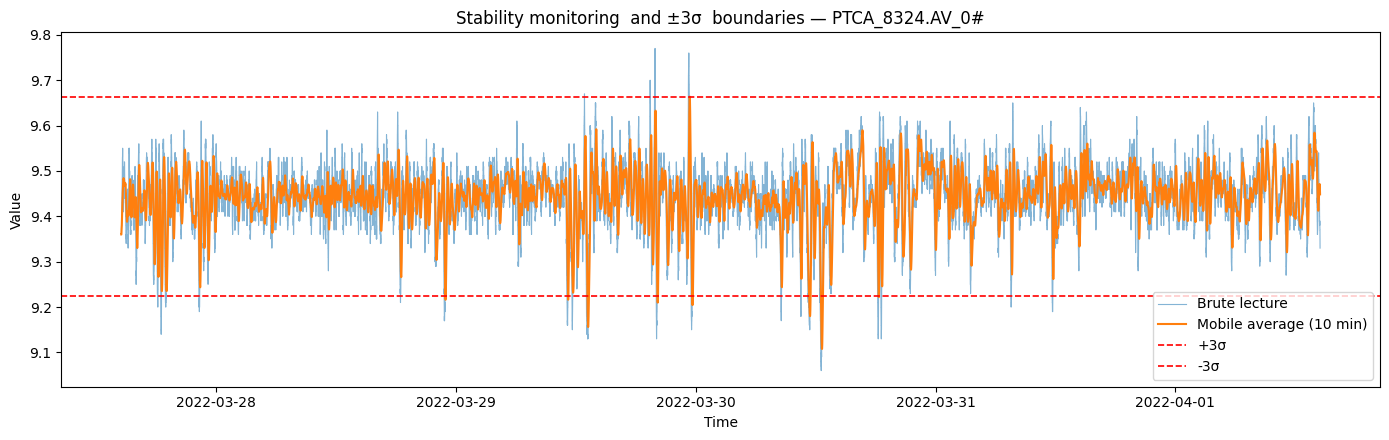

Successfully exported to: /kaggle/working/boiler_powerbi_summary.csv | Rows: 7201


In [75]:
# Dictionary of aggregations per minute over df_min
agg_dict = {}
for col in vars_clave:
  agg_dict[f"{col}_prom"] = (col, "mean")
  agg_dict[f"{col}_min"] = (col, "min")
  agg_dict[f"{col}_max"] = (col, "max")
  agg_dict[f"{col}_std_movil_prom"] = (f"{col}_roll_std", "mean")
  agg_dict[f"{col}_anom_3s_count"] = (
      f"{col}_estado",
      lambda s: (s == "Anomaly (>3s)").sum(),
  )

df_pbi = df_min.agg(**agg_dict).dropna(how="all").reset_index()

output_csv = "/kaggle/working/boiler_powerbi_summary.csv"
df_pbi.to_csv(output_csv, index=False)

# 3. Plot of time series + boundaries +-3 sigma for top variable
var_top = "PTCA_8324.AV_0#"
mu_top = df_analisis[var_top].mean()
sd_top = df_analisis[var_top].std()

plt.figure(figsize=(14, 4.5))
plt.plot(
    df_analisis["date"],
    df_analisis[var_top],
    label="Brute lecture",
    alpha=0.55,
    linewidth=0.8,
)
plt.plot(
    df_analisis["date"],
    df_analisis[f"{var_top}_roll_mean"],
    label="Mobile average (10 min)",
    linewidth=1.5,
)
plt.axhline(
    mu_top + 3 * sd_top, color="red", linestyle="--", linewidth=1.2, label="+3σ"
)
plt.axhline(
    mu_top - 3 * sd_top, color="red", linestyle="--", linewidth=1.2, label="-3σ"
)
plt.title(f"Stability monitoring  and ±3σ  boundaries — {var_top}")
plt.xlabel("Time")
plt.ylabel("Value")
plt.legend()
plt.tight_layout()
plt.show()
print("Successfully exported to:", output_csv, "| Rows:", len(df_pbi))